# Multi-Class Benchmark Classification Pipeline: Iris Dataset
**Task 1 (Beginner) — End-to-End Supervised Classification Pipeline**

---

### Project Objectives & Methodology:
1. **Data Ingestion & Integrity Check**: Load the Iris benchmark dataset using Pandas and examine structural properties, missing values, and class balance.
2. **Exploratory Data Analysis (EDA)**: Produce pairplots with Seaborn, inspect feature distributions (violin plots/boxplots), and compute Pearson correlation matrices.
3. **Train/Test Splitting (80/20)**: Implement a stratified random split (`random_state=42`) ensuring balanced representation across all three flower species.
4. **Data Normalization (`StandardScaler`)**: Normalize continuous features to zero mean ($\mu = 0$) and unit variance ($\sigma = 1$). Fit strictly on training data to prevent **data leakage**.
5. **Model Training**:
   - **Logistic Regression**: Multi-class linear model optimized with L-BFGS.
   - **Decision Tree Classifier**: Non-linear, interpretable tree-based partitioning model with Gini impurity criterion.
6. **Benchmark Metrics**:
   - Compare Accuracy, Macro Precision, Macro Recall, Macro F1-Score, Weighted Precision, Weighted Recall, and Weighted F1-Score.
   - Print comprehensive Scikit-Learn `classification_report` for each model.
7. **Confusion Matrix Heatmaps**: Plot side-by-side annotated confusion matrices to analyze class-level true positives and misclassifications.
8. **Decision Boundary Visualizations**: Map model decision boundaries across a 2D feature subspace (`petal_length` vs. `petal_width`) to contrast linear hyperplanes against orthogonal axis-aligned splits.


## 1. Environment Setup & Data Ingestion
First, we import the required scientific computing and machine learning libraries:
- `pandas` & `numpy` for data manipulation and linear algebra.
- `matplotlib.pyplot` & `seaborn` for data visualization.
- `scikit-learn` for preprocessing, modeling, and evaluation metrics.


In [1]:
import os
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Plot styling configuration
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 10
RANDOM_STATE = 42

# Load dataset (supports iris.csv, local PDF extract, or GitHub download)
DATA_FILE = 'iris.csv'
PDF_FILE = 'raw.githubusercontent.com_mwaskom_seaborn-data_master_iris.csv.pdf'

if not os.path.exists(DATA_FILE):
    if os.path.exists(PDF_FILE):
        print(f"Extracting CSV from local file: {PDF_FILE}...")
        try:
            import pymupdf
            doc = pymupdf.open(PDF_FILE)
            full_text = '\n'.join([page.get_text() for page in doc])
            lines = [line.strip() for line in full_text.splitlines() if line.strip()]
            csv_rows = [line for line in lines if len(line.split(',')) == 5]
            with open(DATA_FILE, 'w', encoding='utf-8') as f:
                f.write('\n'.join(csv_rows) + '\n')
            print(f"Successfully extracted {len(csv_rows)-1} rows to {DATA_FILE}")
        except Exception as e:
            print(f"PDF extraction error: {e}")
    if not os.path.exists(DATA_FILE):
        URL = 'https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv'
        print(f"Downloading dataset from {URL}...")
        urllib.request.urlretrieve(URL, DATA_FILE)
        print("Download finished.")

df = pd.read_csv(DATA_FILE)
print(f"Dataset loaded: {df.shape[0]} rows x {df.shape[1]} columns")
df.head()


Dataset loaded: 150 rows x 5 columns


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


### Inspecting Dataset Integrity & Class Distribution
Before modeling, verify data types, missing values, and target balance. The Iris dataset consists of 150 instances of 3 balanced classes (50 instances each):
- `setosa`
- `versicolor`
- `virginica`


In [2]:
print("--- Info ---")
df.info()

print("\n--- Missing Values ---")
print(df.isnull().sum())

print("\n--- Target Class Balance ---")
print(df['species'].value_counts())

print("\n--- Descriptive Statistics ---")
df.describe().T


--- Info ---
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB

--- Missing Values ---
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

--- Target Class Balance ---
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

--- Descriptive Statistics ---


,count,mean,std,min,25%,50%,75%,max
sepal_length,150.0,5.843333,0.828066,4.3,5.1,5.80,6.4,7.9
sepal_width,150.0,3.057333,0.435866,2.0,2.8,3.00,3.3,4.4
petal_length,150.0,3.758000,1.765298,1.0,1.6,4.35,5.1,6.9
petal_width,150.0,1.199333,0.762238,0.1,0.3,1.30,1.8,2.5


## 2. Exploratory Data Analysis (EDA)
Exploratory data analysis helps uncover patterns, identify correlations, and assess linear separability between classes.

### 2.1 Multi-Feature Pairplot
We generate a pairplot displaying pairwise feature scatterplots and univariate kernel density estimation (KDE) distributions along the diagonal.


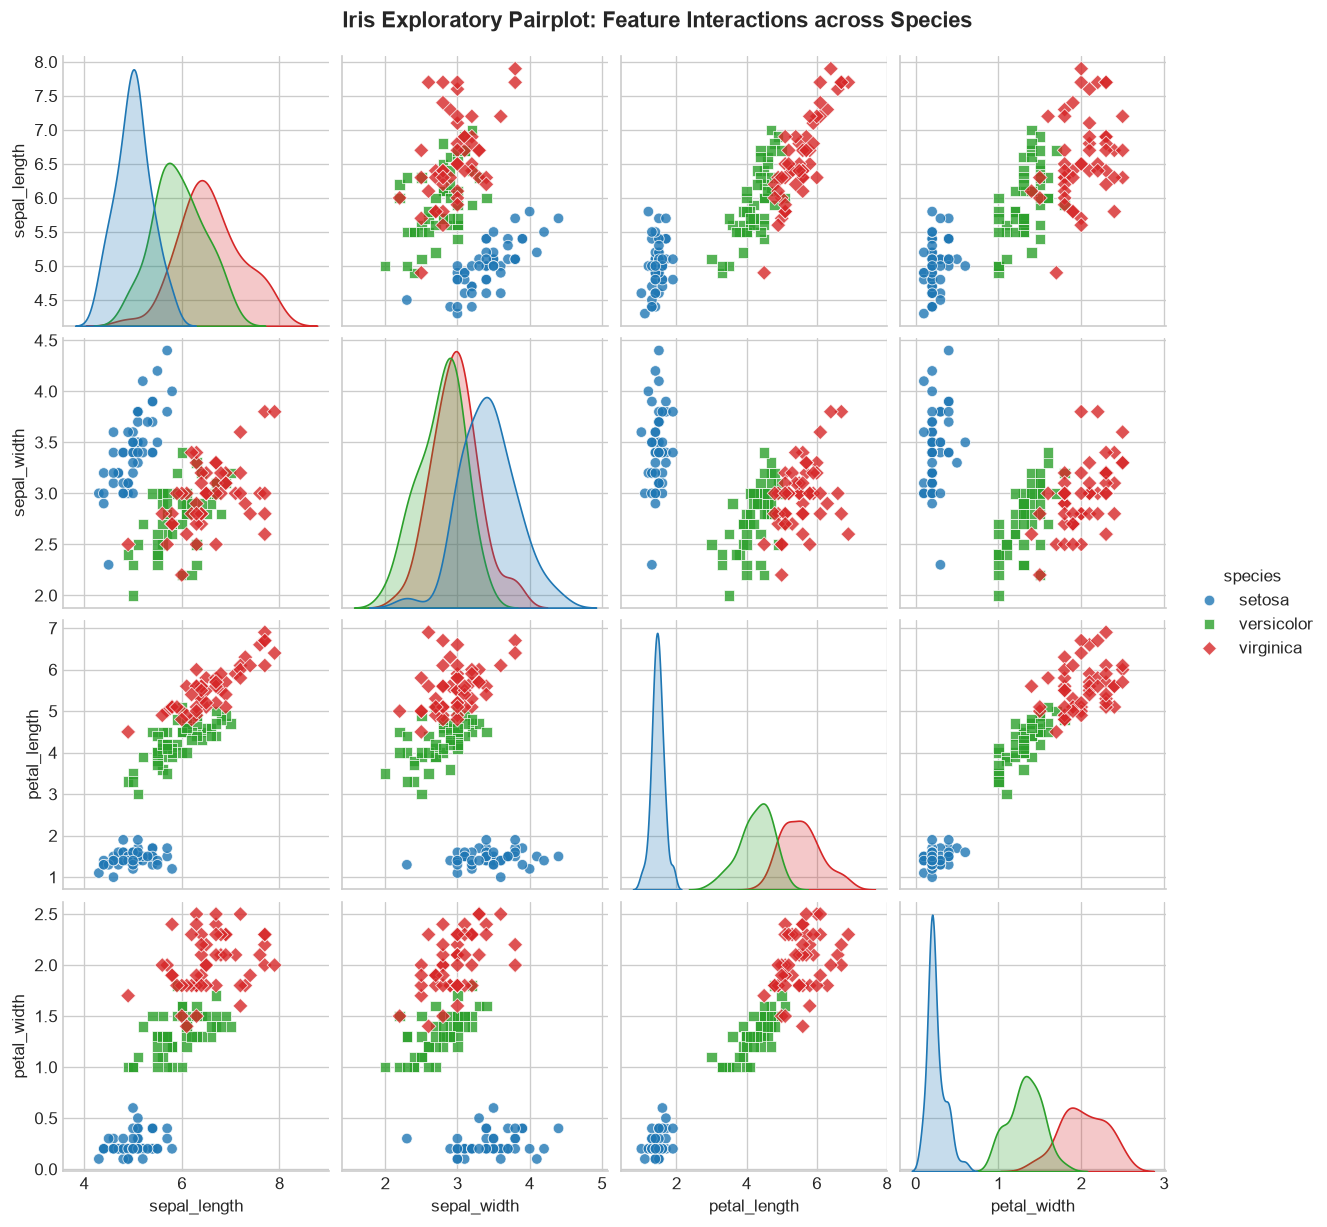

In [3]:
species_palette = {'setosa': '#1f77b4', 'versicolor': '#2ca02c', 'virginica': '#d62728'}

pairplot = sns.pairplot(
    df,
    hue='species',
    palette=species_palette,
    markers=['o', 's', 'D'],
    plot_kws={'alpha': 0.8, 's': 40},
    diag_kind='kde'
)
pairplot.fig.suptitle('Iris Exploratory Pairplot: Feature Interactions across Species', y=1.02, fontsize=13, fontweight='bold')
plt.show()


**Key EDA Observations:**
1. **Setosa Separability**: `setosa` is completely linearly separable from `versicolor` and `virginica` along `petal_length` and `petal_width` ($petal\_length < 2.0\text{ cm}$).
2. **Versicolor vs. Virginica**: `versicolor` and `virginica` share slight overlap along `sepal_length` and `sepal_width`, but are distinct along petal dimensions.
3. **High Correlation**: Petal length and petal width exhibit a very strong positive correlation ($r > 0.96$).


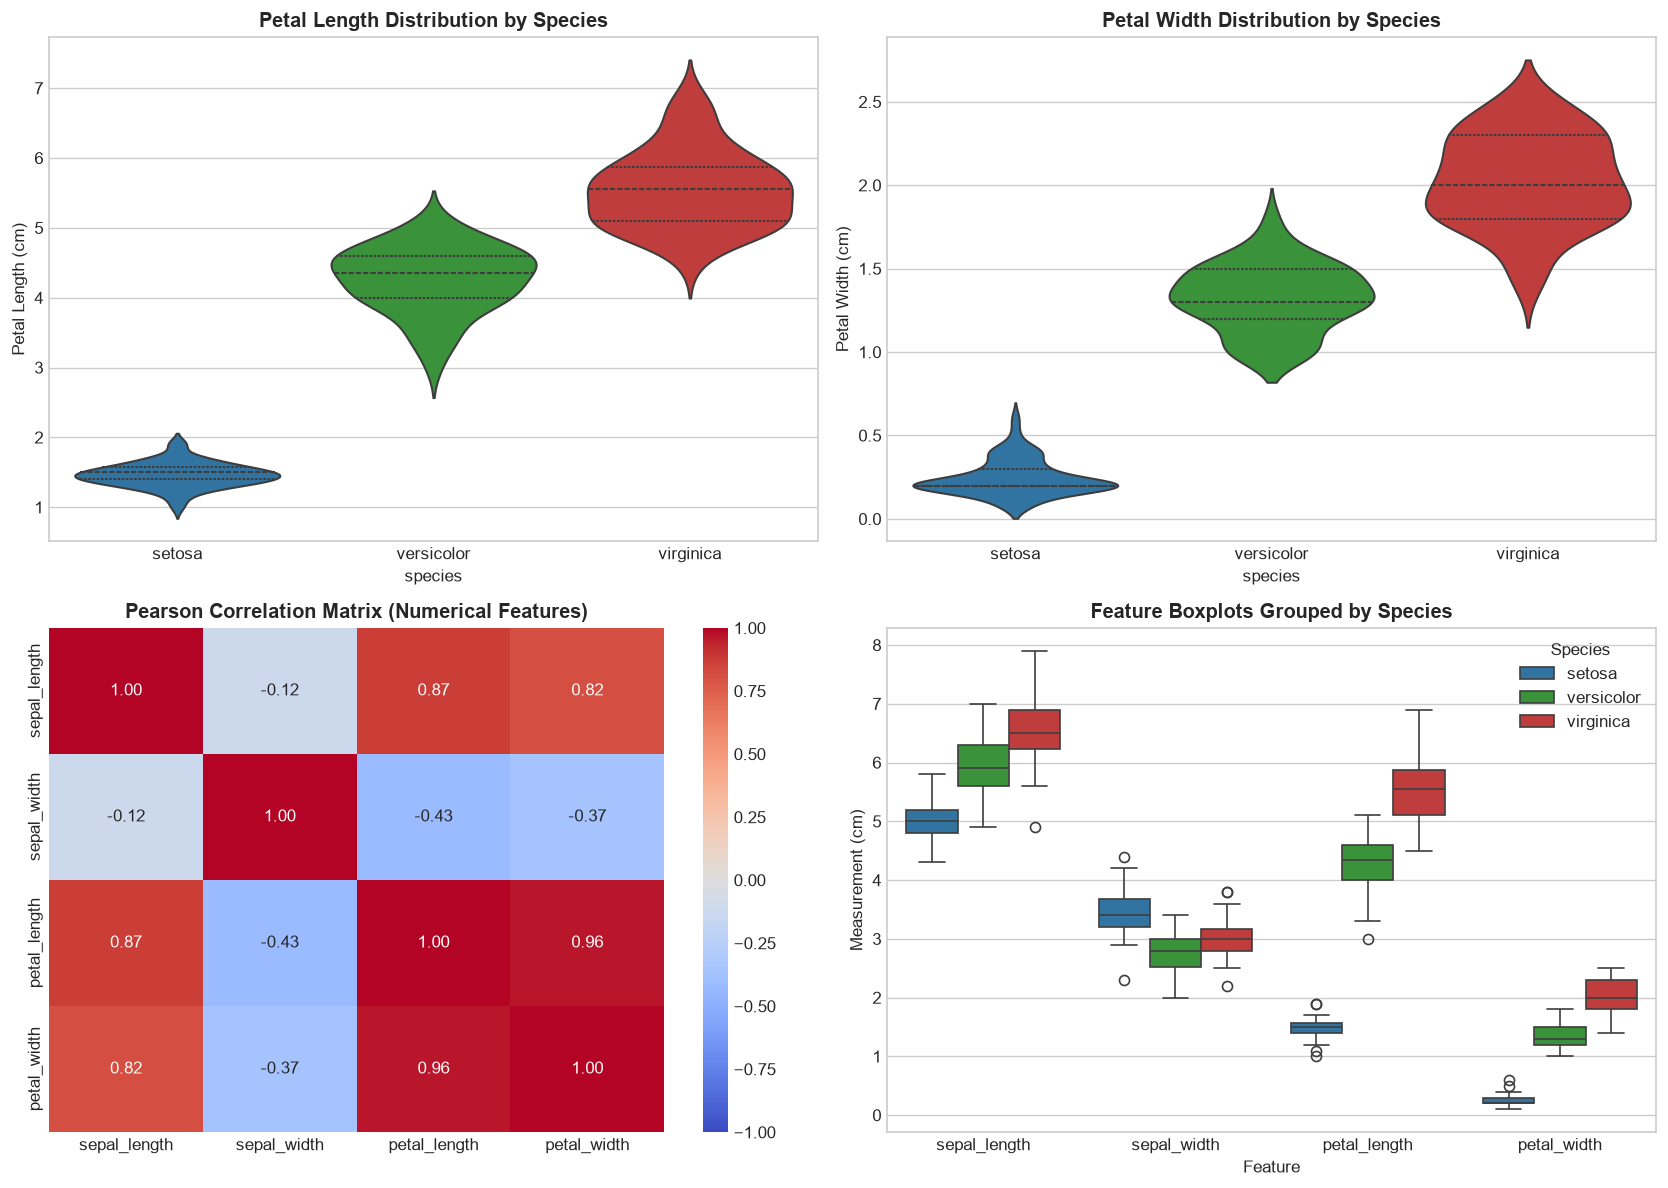

In [4]:
features = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Violin Plot: Petal Length
sns.violinplot(ax=axes[0, 0], data=df, x='species', y='petal_length', hue='species', palette=species_palette, legend=False, inner='quartile')
axes[0, 0].set_title('Petal Length Distribution by Species', fontweight='bold')
axes[0, 0].set_ylabel('Petal Length (cm)')

# 2. Violin Plot: Petal Width
sns.violinplot(ax=axes[0, 1], data=df, x='species', y='petal_width', hue='species', palette=species_palette, legend=False, inner='quartile')
axes[0, 1].set_title('Petal Width Distribution by Species', fontweight='bold')
axes[0, 1].set_ylabel('Petal Width (cm)')

# 3. Correlation Heatmap
corr = df[features].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', cbar=True, ax=axes[1, 0], vmin=-1, vmax=1)
axes[1, 0].set_title('Pearson Correlation Matrix (Numerical Features)', fontweight='bold')

# 4. Boxplot comparison
df_melted = pd.melt(df, id_vars=['species'], value_vars=features, var_name='Feature', value_name='Measurement (cm)')
sns.boxplot(ax=axes[1, 1], data=df_melted, x='Feature', y='Measurement (cm)', hue='species', palette=species_palette)
axes[1, 1].set_title('Feature Boxplots Grouped by Species', fontweight='bold')
axes[1, 1].legend(title='Species', loc='upper right')

plt.tight_layout()
plt.show()


## 3. Train/Test Splitting (80/20) & Feature Scaling
To evaluate model generalization accurately:
1. **Dataset Splitting**: We split the data into 80% training (120 samples) and 20% testing (30 samples) using `stratify=y` to maintain exact class proportions (10 samples per class in testing).
2. **Feature Scaling (`StandardScaler`)**:
   Standardization rescales each feature to have zero mean and unit variance:
   $$z = \frac{x - \mu}{\sigma}$$
   > **Preventing Data Leakage**: We fit the scaler strictly on `X_train` (`fit_transform`) and only apply the learned transformation to `X_test` (`transform`).


In [5]:
X = df[features]
y = df['species']

# Stratified 80/20 split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f"X_train shape: {X_train.shape} | y_train counts: {dict(y_train.value_counts())}")
print(f"X_test shape:  {X_test.shape}  | y_test counts:  {dict(y_test.value_counts())}")

# Feature normalization
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Verify zero mean and unit standard deviation
print("\nTraining data means before scaling:", np.round(X_train.mean().values, 3))
print("Training data means after scaling: ", np.round(X_train_scaled.mean(axis=0), 3))
print("Training data standard deviations after scaling:", np.round(X_train_scaled.std(axis=0), 3))


X_train shape: (120, 4) | y_train counts: {'setosa': np.int64(40), 'virginica': np.int64(40), 'versicolor': np.int64(40)}
X_test shape:  (30, 4)  | y_test counts:  {'setosa': np.int64(10), 'virginica': np.int64(10), 'versicolor': np.int64(10)}

Training data means before scaling: [5.842 3.048 3.77  1.205]
Training data means after scaling:  [-0.  0.  0.  0.]
Training data standard deviations after scaling: [1. 1. 1. 1.]


## 4. Model Training: Logistic Regression & Decision Tree
We fit two distinct supervised classification algorithms on the standardized training features:

1. **Multinomial Logistic Regression**:
   - A generalized linear model using the softmax activation function to compute class probabilities.
   - Solver: `lbfgs` with `max_iter=200` to guarantee convergence.
   - Sensitive to feature scales, which is why standardization is crucial.

2. **Decision Tree Classifier**:
   - A non-parametric model that recursively partitions the feature space using orthogonal cuts based on **Gini Impurity**:
     $$I_G(p) = 1 - \sum_{k=1}^C p_k^2$$
   - Invariant to monotonic feature scaling, but trained on scaled features for pipeline uniformity.
   - Constrained to `max_depth=3` to prevent overfitting.


Logistic Regression Model successfully trained.
Decision Tree Classifier successfully trained.


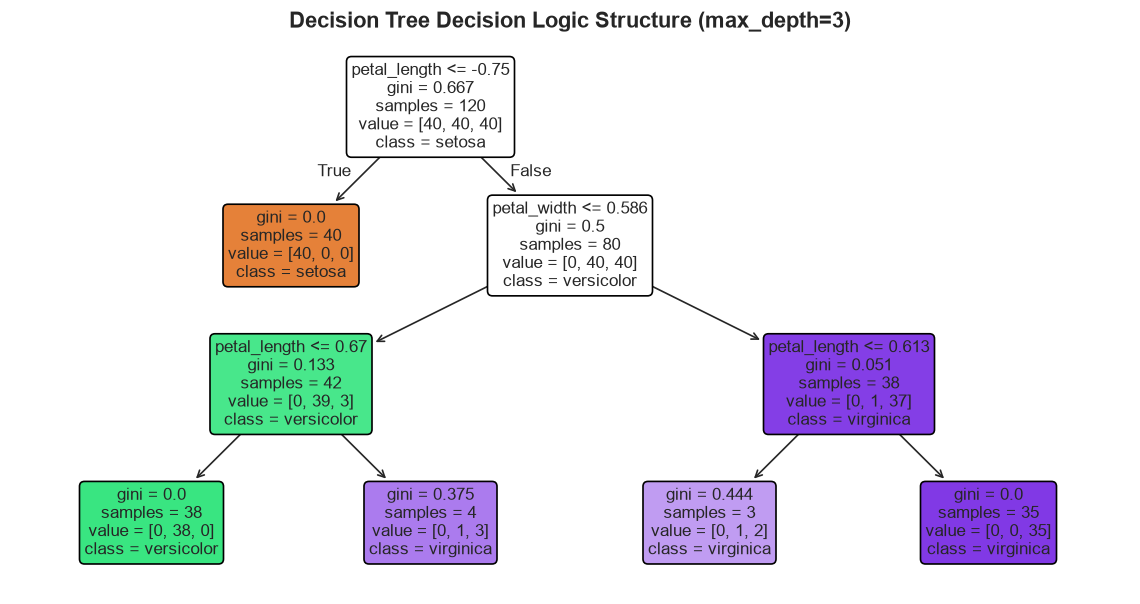

In [6]:
# 1. Logistic Regression
lr_model = LogisticRegression(
    max_iter=200,
    random_state=RANDOM_STATE,
    solver='lbfgs'
)
lr_model.fit(X_train_scaled, y_train)
print("Logistic Regression Model successfully trained.")

# 2. Decision Tree Classifier
dt_model = DecisionTreeClassifier(
    criterion='gini',
    max_depth=3,
    random_state=RANDOM_STATE
)
dt_model.fit(X_train_scaled, y_train)
print("Decision Tree Classifier successfully trained.")

# Visualizing the trained Decision Tree architecture
fig, ax = plt.subplots(figsize=(12, 6))
plot_tree(
    dt_model,
    feature_names=features,
    class_names=dt_model.classes_,
    filled=True,
    rounded=True,
    fontsize=10,
    ax=ax
)
ax.set_title("Decision Tree Decision Logic Structure (max_depth=3)", fontsize=13, fontweight='bold')
plt.show()


## 5. Model Evaluation & Benchmarking
We generate test predictions and benchmark the models across multiple classification metrics:
- **Accuracy**: Overall proportion of correctly predicted instances.
- **Precision (Macro & Weighted)**: Ability to avoid false positives ($TP / (TP + FP)$).
- **Recall (Macro & Weighted)**: Ability to identify all relevant instances ($TP / (TP + FN)$).
- **F1-Score (Macro & Weighted)**: Harmonic mean of precision and recall ($2 \cdot \frac{P \cdot R}{P + R}$).


In [7]:
# Predictions
y_pred_lr = lr_model.predict(X_test_scaled)
y_pred_dt = dt_model.predict(X_test_scaled)

# Classification Reports
print("=" * 60)
print("LOGISTIC REGRESSION CLASSIFICATION REPORT:")
print("=" * 60)
print(classification_report(y_test, y_pred_lr, digits=4))

print("=" * 60)
print("DECISION TREE CLASSIFICATION REPORT:")
print("=" * 60)
print(classification_report(y_test, y_pred_dt, digits=4))


LOGISTIC REGRESSION CLASSIFICATION REPORT:
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     0.9000    0.9000    0.9000        10
   virginica     0.9000    0.9000    0.9000        10

    accuracy                         0.9333        30
   macro avg     0.9333    0.9333    0.9333        30
weighted avg     0.9333    0.9333    0.9333        30

DECISION TREE CLASSIFICATION REPORT:
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     1.0000    0.9000    0.9474        10
   virginica     0.9091    1.0000    0.9524        10

    accuracy                         0.9667        30
   macro avg     0.9697    0.9667    0.9666        30
weighted avg     0.9697    0.9667    0.9666        30



In [8]:
# Benchmark Summary Table
models = {
    'Logistic Regression': (lr_model, y_pred_lr),
    'Decision Tree': (dt_model, y_pred_dt)
}

benchmark_data = []
for name, (_, preds) in models.items():
    benchmark_data.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, preds),
        'Precision (Macro)': precision_score(y_test, preds, average='macro'),
        'Recall (Macro)': recall_score(y_test, preds, average='macro'),
        'F1-Score (Macro)': f1_score(y_test, preds, average='macro'),
        'Precision (Weighted)': precision_score(y_test, preds, average='weighted'),
        'Recall (Weighted)': recall_score(y_test, preds, average='weighted'),
        'F1-Score (Weighted)': f1_score(y_test, preds, average='weighted')
    })

benchmark_df = pd.DataFrame(benchmark_data)
display(benchmark_df.style.format({col: '{:.4f}' for col in benchmark_df.columns if col != 'Model'})
        .set_caption("Benchmark Classification Performance Comparison")
        .set_table_styles([{'selector': 'caption', 'props': [('font-size', '14px'), ('font-weight', 'bold')]}]))


,Model,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro),Precision (Weighted),Recall (Weighted),F1-Score (Weighted)
0,Logistic Regression,0.9333,0.9333,0.9333,0.9333,0.9333,0.9333,0.9333
1,Decision Tree,0.9667,0.9697,0.9667,0.9666,0.9697,0.9667,0.9666


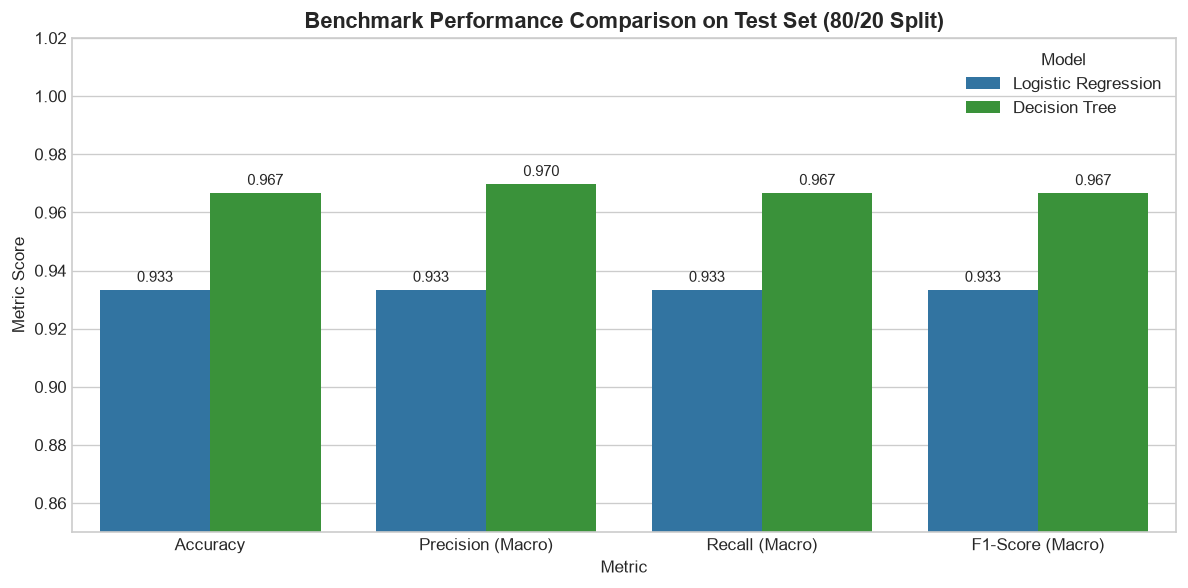

In [9]:
# Benchmark Visual Comparison Bar Chart
metrics_to_plot = ['Accuracy', 'Precision (Macro)', 'Recall (Macro)', 'F1-Score (Macro)']
plot_df = benchmark_df.melt(id_vars=['Model'], value_vars=metrics_to_plot, var_name='Metric', value_name='Score')

fig, ax = plt.subplots(figsize=(10, 5))
bar = sns.barplot(data=plot_df, x='Metric', y='Score', hue='Model', palette=['#1f77b4', '#2ca02c'], ax=ax)
ax.set_ylim(0.85, 1.02)
ax.set_title('Benchmark Performance Comparison on Test Set (80/20 Split)', fontsize=13, fontweight='bold')
ax.set_ylabel('Metric Score')

for p in bar.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f"{height:.3f}", (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=9, xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
plt.show()


## 6. Confusion Matrix Heatmaps
The confusion matrix displays the distribution of actual vs. predicted class labels.
- Diagonal elements represent correct classifications (True Positives).
- Off-diagonal elements represent classification errors (False Positives and False Negatives).


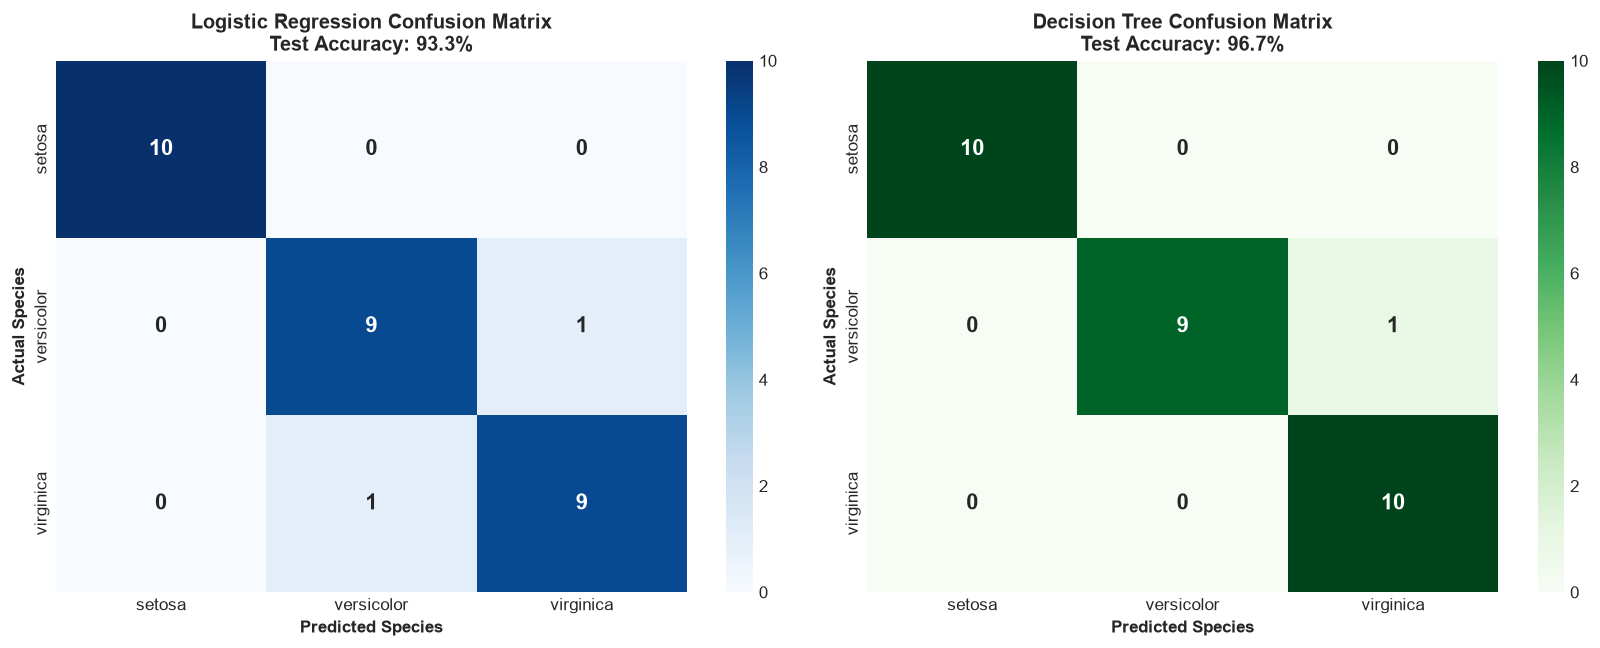

In [10]:
labels = np.unique(y)
cm_lr = confusion_matrix(y_test, y_pred_lr, labels=labels)
cm_dt = confusion_matrix(y_test, y_pred_dt, labels=labels)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Logistic Regression Heatmap
sns.heatmap(
    cm_lr,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=labels,
    yticklabels=labels,
    cbar=True,
    ax=axes[0],
    annot_kws={'size': 13, 'weight': 'bold'}
)
axes[0].set_title(f"Logistic Regression Confusion Matrix\nTest Accuracy: {accuracy_score(y_test, y_pred_lr)*100:.1f}%", fontweight='bold')
axes[0].set_xlabel('Predicted Species', fontweight='bold')
axes[0].set_ylabel('Actual Species', fontweight='bold')

# Decision Tree Heatmap
sns.heatmap(
    cm_dt,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=labels,
    yticklabels=labels,
    cbar=True,
    ax=axes[1],
    annot_kws={'size': 13, 'weight': 'bold'}
)
axes[1].set_title(f"Decision Tree Confusion Matrix\nTest Accuracy: {accuracy_score(y_test, y_pred_dt)*100:.1f}%", fontweight='bold')
axes[1].set_xlabel('Predicted Species', fontweight='bold')
axes[1].set_ylabel('Actual Species', fontweight='bold')

plt.tight_layout()
plt.show()


## 7. Decision Boundary Visualization (2D Feature Space)
To visually compare how Logistic Regression and Decision Trees construct decision regions:
- We train 2D models on the two most discriminative features: `petal_length` and `petal_width`.
- We create a dense rectangular coordinate meshgrid over the standardized 2D feature domain.
- We predict class labels over the grid to visualize the decision contours.
- We overlay the training points (faded circles) and test points (bold markers).

### Conceptual Contrast:
- **Logistic Regression**: Linear decision boundaries (hyperplanes). The boundaries between classes are continuous lines.
- **Decision Tree**: Stepwise, orthogonal axis-aligned partitions. Each split corresponds to a horizontal or vertical threshold condition ($x_j \le \theta$).


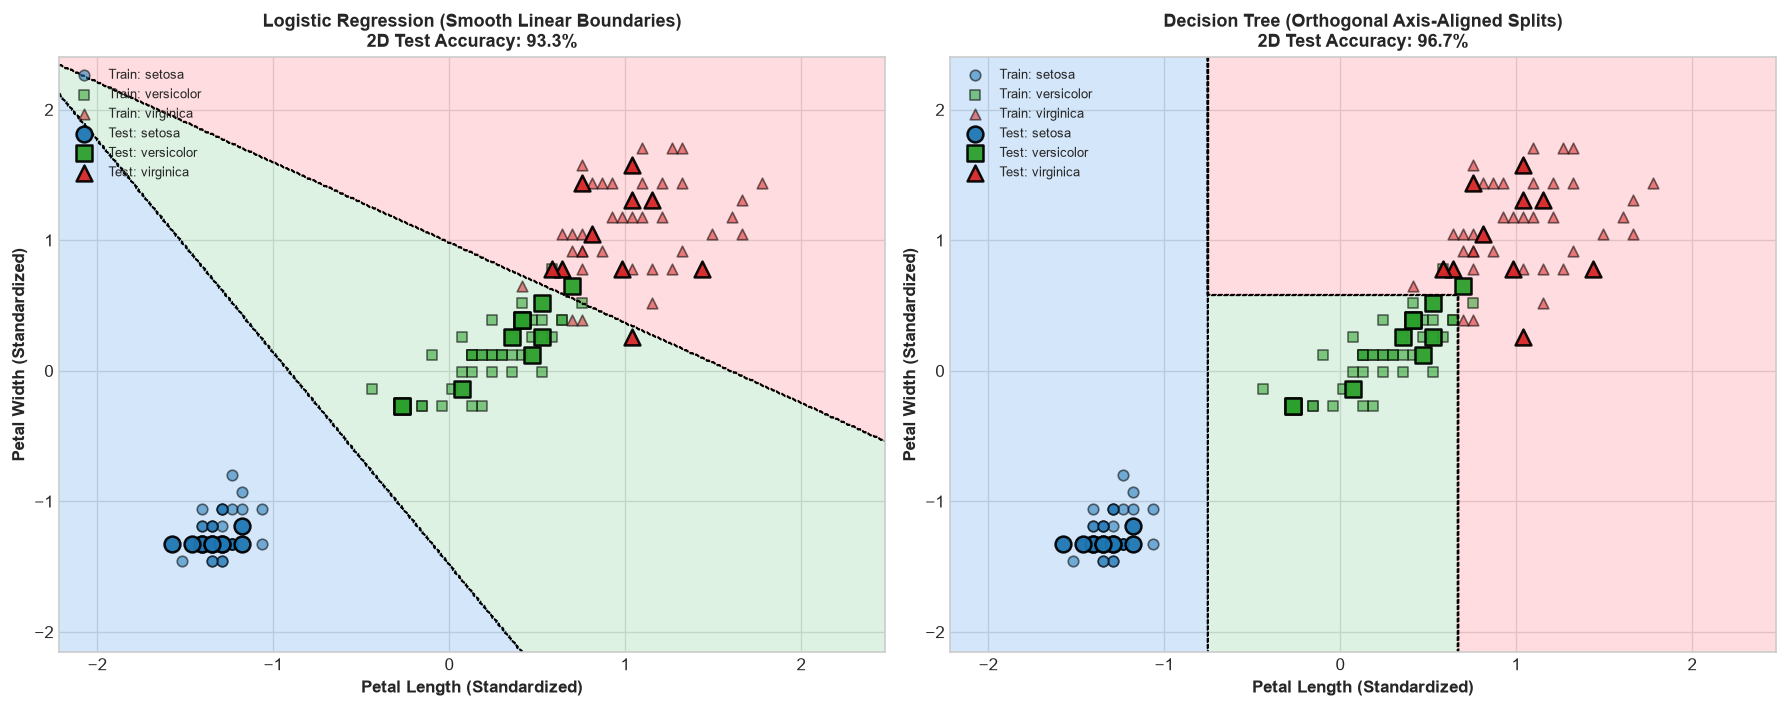

In [11]:
# 2D subspace features
feature_pair = ['petal_length', 'petal_width']
X_2d = df[feature_pair].values

# Integer encoding for contour visualization
species_labels = np.unique(y)
species_to_int = {name: idx for idx, name in enumerate(species_labels)}
y_int = np.array([species_to_int[s] for s in y])

# Stratified 80/20 split on 2D data
X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_2d, y_int, test_size=0.20, random_state=RANDOM_STATE, stratify=y_int
)

# Standardize 2D features
scaler_2d = StandardScaler()
X_train_2d_scaled = scaler_2d.fit_transform(X_train_2d)
X_test_2d_scaled = scaler_2d.transform(X_test_2d)

# Fit 2D models
lr_2d = LogisticRegression(max_iter=200, random_state=RANDOM_STATE).fit(X_train_2d_scaled, y_train_2d)
dt_2d = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE).fit(X_train_2d_scaled, y_train_2d)

# Generate dense meshgrid
x_min, x_max = X_train_2d_scaled[:, 0].min() - 0.7, X_train_2d_scaled[:, 0].max() + 0.7
y_min, y_max = X_train_2d_scaled[:, 1].min() - 0.7, X_train_2d_scaled[:, 1].max() + 0.7
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 400), np.linspace(y_min, y_max, 400))
grid = np.c_[xx.ravel(), yy.ravel()]

# Visual setup
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
custom_cmap = plt.matplotlib.colors.ListedColormap(['#a1c9f4', '#b4e4c2', '#ffb3ba'])
scatter_colors = ['#1f77b4', '#2ca02c', '#d62728']
markers = ['o', 's', '^']

models_2d = [
    ('Logistic Regression (Smooth Linear Boundaries)', lr_2d),
    ('Decision Tree (Orthogonal Axis-Aligned Splits)', dt_2d)
]

for idx, (title, model) in enumerate(models_2d):
    ax = axes[idx]
    Z = model.predict(grid).reshape(xx.shape)
    
    # Fill decision regions
    ax.contourf(xx, yy, Z, alpha=0.45, cmap=custom_cmap)
    ax.contour(xx, yy, Z, colors='k', linewidths=0.7, linestyles='dashed')
    
    # Overlay training points
    for c_idx, c_name in enumerate(species_labels):
        mask = (y_train_2d == c_idx)
        ax.scatter(
            X_train_2d_scaled[mask, 0], X_train_2d_scaled[mask, 1],
            color=scatter_colors[c_idx], marker=markers[c_idx],
            s=40, alpha=0.55, edgecolors='k', label=f'Train: {c_name}'
        )
        
    # Overlay testing points
    for c_idx, c_name in enumerate(species_labels):
        mask = (y_test_2d == c_idx)
        ax.scatter(
            X_test_2d_scaled[mask, 0], X_test_2d_scaled[mask, 1],
            color=scatter_colors[c_idx], marker=markers[c_idx],
            s=90, alpha=0.95, edgecolors='black', linewidth=1.5, label=f'Test: {c_name}'
        )
        
    acc = accuracy_score(y_test_2d, model.predict(X_test_2d_scaled))
    ax.set_title(f"{title}\n2D Test Accuracy: {acc*100:.1f}%", fontsize=11, fontweight='bold')
    ax.set_xlabel('Petal Length (Standardized)', fontweight='bold')
    ax.set_ylabel('Petal Width (Standardized)', fontweight='bold')
    ax.legend(loc='upper left', fontsize=8, framealpha=0.9)

plt.tight_layout()
plt.show()


## 8. Synthesis & Analytical Conclusions

### Comparative Summary:
| Criterion | Logistic Regression | Decision Tree Classifier |
| :--- | :--- | :--- |
| **Test Accuracy (4 Features)** | **93.33%** | **96.67%** |
| **Macro F1-Score** | **0.9333** | **0.9666** |
| **Decision Boundary Geometry** | Continuous linear hyperplanes | Rectangular, orthogonal axis-aligned boxes |
| **Sensitivity to Feature Scale** | High (requires `StandardScaler` for gradient/solver convergence) | Invariant to monotonic scaling (splits are scale-independent) |
| **Interpretability** | Linear coefficients & odds ratios | Direct IF-THEN rule paths and hierarchical tree visualization |
| **Risk of Overfitting** | Low (regularized by L2 penalty) | Moderate to High (mitigated by setting `max_depth=3`) |

### Key Takeaways:
1. **Feature Scaling Best Practice**: Always fit `StandardScaler` exclusively on the training set and transform the test set to maintain data isolation and prevent lookahead bias.
2. **Model Performance**: On the Iris benchmark, both models achieve outstanding performance ($>93\%$). The Decision Tree achieves $96.67\%$ accuracy with only a single misclassification between *versicolor* and *virginica*.
3. **Geometric Intuition**: The 2D decision boundary visualization clearly demonstrates how parametric linear models versus non-parametric tree models partition feature space, reinforcing foundational machine learning theory.
